Requires conda to install cctbx

Install other dependencies with pip

331be1ef-d48c-41e1-8479-451d0912be8c,1,6,Ir2Sc2Yb2,PyXtal,25
b41d0516-a5fd-4785-adc2-5b5257048df9,7,25,Ho2Ti2,PyXtal,85
b8a70760-d7b9-49d9-93bf-74696d8978c3,81,207,B9Er36V3,PyXtal,275

# Add to database

In [304]:
sample_index=16

In [305]:
import sqlite3
import csv

# Connect to your SQLite database
conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

structure_csv = "1k_structures.csv"

cursor.execute("""
    DROP TABLE IF EXISTS Structures
""")

# Load the CSV
with open(structure_csv, newline='') as csvfile:
    reader = csv.DictReader(csvfile)
    for row in reader:
        # Create the table once before the loop
        cursor.execute("""
            CREATE TABLE IF NOT EXISTS Structures (
                structure_id,
                source,
                generation_commit,
                extinction_group,
                crystal_system,
                space_group,
                composition,
                lattice_a,
                lattice_b,
                lattice_c,
                alpha,
                beta,
                gamma,
                atom_sites_json
            )
        """)

        # Then inside the loop, use only INSERT INTO
        cursor.execute("""
            INSERT INTO Structures (
                structure_id, source, generation_commit, extinction_group, crystal_system, 
                space_group, composition, lattice_a, lattice_b, lattice_c,
                alpha, beta, gamma, atom_sites_json
            ) VALUES ( ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """, (  row["structure_id"],
                row["source"],
                #row["source_id"],
                row["generation_commit"],
                #row["extinction_class"],
                int(row["extinction_group"]),
                row["crystal_system"],
                int(row["space_group"]),
                row["composition"],
                float(row["lattice_a"]),
                float(row["lattice_b"]),
                float(row["lattice_c"]),
                float(row["alpha"]),
                float(row["beta"]),
                float(row["gamma"]),
                #row["wyckoff_positions"],
                row["atoms"]))
        
# Commit and close
conn.commit()
conn.close()

print("All structure rows (with space group) loaded into the database successfully!")


All structure rows (with space group) loaded into the database successfully!


 # Verify upload

In [306]:
import sqlite3
import csv

# Connect to your database
conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM Structures")
count = cursor.fetchone()[0]
print(f"Number of rows in table: {count}")

Number of rows in table: 1000


# Check first entry

In [307]:
import sqlite3

# Connect to your database
conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

# Example query: select everything
cursor.execute("SELECT * FROM Structures")

# Fetch all rows (you can also use fetchone() or fetchmany())
rows = cursor.fetchall()

# Optional: get column names
columns = [description[0] for description in cursor.description]

# Print nicely
for row in rows:
    record = dict(zip(columns, row))
    print(record)
    break

# Close connection
conn.close()


{'structure_id': '331be1ef-d48c-41e1-8479-451d0912be8c', 'source': 'PyXtal', 'generation_commit': '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 'extinction_group': 1, 'crystal_system': 'Monoclinic', 'space_group': 6, 'composition': 'Ir2Sc2Yb2', 'lattice_a': 6.2824886330621945, 'lattice_b': 4.79225379515856, 'lattice_c': 5.521027253930496, 'alpha': 90.0, 'beta': 100.75613636611877, 'gamma': 90.0, 'atom_sites_json': "[{'symbol': 'Sc', 'position': array([0.92383867, 0.24375713, 0.65795994])}, {'symbol': 'Sc', 'position': array([0.92383867, 0.75624287, 0.65795994])}, {'symbol': 'Yb', 'position': array([0.3819144 , 0.        , 0.71845362])}, {'symbol': 'Yb', 'position': array([9.72797476e-02, 8.15776052e-34, 5.88539094e-02])}, {'symbol': 'Ir', 'position': array([0.52261759, 0.5       , 0.2992619 ])}, {'symbol': 'Ir', 'position': array([1.07664725e-01, 2.46901921e-33, 3.84604954e-01])}]"}


# Check entry using HDF5 index

In [308]:
import csv

hdf5_to_structure = {}

with open("interp_metadata_clean.csv", newline="") as f:
    reader = csv.DictReader(
        row for row in f if not row.lstrip().startswith("#")
    )
    for row in reader:
        hdf5_to_structure[int(row["hdf5_index"])] = row["structure_id"]

print(hdf5_to_structure[1])

c39d7883-927b-470f-8035-34ee71681b8a


In [309]:
hdf5_to_structure[sample_index]

'2a91c741-6c57-4b06-a775-8ccedcdbf0e3'

In [310]:
hdf5_to_structure[85]

'b41d0516-a5fd-4785-adc2-5b5257048df9'

In [311]:
hdf5_to_structure[275]

'b8a70760-d7b9-49d9-93bf-74696d8978c3'

# Extract all metadata

In [312]:
import sqlite3

conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

cursor.execute("""
    SELECT *
    FROM Structures
    WHERE structure_id = ?
""", (hdf5_to_structure[sample_index],))

row = cursor.fetchone()
conn.close()

print(row)

('2a91c741-6c57-4b06-a775-8ccedcdbf0e3', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 75, 'Trigonal', 146, 'Ra9Yb3', 10.977213436922739, 10.977213436922739, 6.592885200222869, 90.0, 90.0, 119.99999999999999, "[{'symbol': 'Yb', 'position': array([0.       , 0.       , 0.8903853])}, {'symbol': 'Yb', 'position': array([0.66666667, 0.33333333, 0.22371863])}, {'symbol': 'Yb', 'position': array([0.33333333, 0.66666667, 0.55705197])}, {'symbol': 'Ra', 'position': array([0.77378134, 0.24136247, 0.67659528])}, {'symbol': 'Ra', 'position': array([0.75863753, 0.53241887, 0.67659528])}, {'symbol': 'Ra', 'position': array([0.46758113, 0.22621866, 0.67659528])}, {'symbol': 'Ra', 'position': array([0.44044801, 0.5746958 , 0.00992861])}, {'symbol': 'Ra', 'position': array([0.4253042 , 0.86575221, 0.00992861])}, {'symbol': 'Ra', 'position': array([0.13424779, 0.55955199, 0.00992861])}, {'symbol': 'Ra', 'position': array([0.10711467, 0.90802913, 0.34326194])}, {'symbol': 'Ra', 'position': array

## Generate allowed reflections (using full information)

In [313]:
from numpy import sin, radians, tan, sqrt

In [314]:
def twotheta_to_d(twotheta, wavelength=1.54):
    """
    Convert 2-theta to d-spacing.
    """
    return wavelength / (2 * sin(radians(twotheta) / 2))


def calcgaussian(x,fwhm):
    """"
    Calculate the cagliotti peakshape for a given center and width.
    The width is the full width at half maximum (FWHM).
    The center is the position of the peak.
    """
    sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
    return np.exp(-0.5 * ((x / sigma) ** 2))

In [315]:

class Peak(object):
    scaleFactor = 1
    def __init__(self, center, u, v, w, I, hkl=[None, None, None], shape="Gaussian", eta=0):
        self.center = center    # 2*theta position
        #note that the keyword argument is not great for hkl.  
        self.u = u
        self.v = v
        self.w = w
        self.I = I
        self.shape = shape
        self.eta = eta
        try:
            self.H = np.sqrt(u*(tan(radians(center/2))**2)
                          + v*tan(radians(center/2)) + w)
            self.scale = self.I * Peak.scaleFactor
        except ValueError:
            self.H = 0
            self.scale = 0
        self.hkl = hkl

    # __call__: returns the value of the Peak at some 2*theta positions
    def __call__(self, x):
        if self.shape.lower() == 'gaussian':
            return self.scale * calcgaussian(x-self.center, self.H)
            #return [self.scale * calcgaussian(value-self.center, self.H) for value in x]
        elif self.shape.lower() == 'pseudovoigt':
            return [self.scale * funcs.calcpseudovoigt(value-self.center, self.H, float(self.eta)) for value in x]
        elif self.shape.lower() == 'lorentzian':
            return [self.scale * funcs.calclorentzian(value-self.center, self.H) for value in x]
        else:
            print(f"Unsupported Peak-shape: {self.shape}\n")
            quit()
    def add(self, v, x):
        # only add to nearby 2*theta positions
        idx = (x>self.center-self.H*3) & (x<self.center+self.H*3)
        try:
            v[idx] += self.__call__(np.array(x)[idx])
        except:
            pass

In [316]:
def generate_diffraction_pattern_helper(spacegroup_number, unit_cell, wavelength, twotheta_min, twotheta_max, twothstep, u, v, w, peak_scale=1000):
    """
    Generate a diffraction pattern for a given space group and unit cell.

    Parameters:
        spacegroup_number (int): Space group number.
        unit_cell (tuple): Unit cell parameters (a, b, c, alpha, beta, gamma).
        wavelength (float): Wavelength of the X-ray beam.
        twotheta_min (float): Minimum 2-theta value.
        twotheta_max (float): Maximum 2-theta value.
        twothstep (float): Step size for 2-theta.
        u, v, w (float): Peak shape parameters.
        peak_scale (float): Scale factor for peak intensity.

    Returns:
        tuple: (twotheta, I) where `twotheta` is an array of 2-theta values and `I` is the corresponding intensity array.
    """
    # Create symmetry object
    symmetry = crystal.symmetry(unit_cell=unit_cell, space_group=spacegroup_number)

    # Calculate d-spacing range
    d_max = twotheta_to_d(twotheta_min, wavelength=wavelength)
    d_min = twotheta_to_d(twotheta_max, wavelength=wavelength)

    # Build Miller set and get allowed reflections
    miller_set = symmetry.build_miller_set(anomalous_flag=False, d_min=d_min, d_max=d_max)
    allowed_reflections = miller_set.indices()
    uc = symmetry.unit_cell()

    # Initialize 2-theta and intensity arrays
    twotheta = np.arange(twotheta_min, twotheta_max, twothstep)
    I = np.zeros(len(twotheta))

    # Calculate intensity for each allowed reflection
    for hkl in allowed_reflections:
        d_spacing = uc.d(hkl)
        twotheta_center = 2 * np.arcsin(wavelength / (2 * d_spacing)) * 180 / np.pi
        ps=np.random.uniform(5, peak_scale)
        peak = Peak(twotheta_center, u, v, w, ps, hkl=hkl, shape="Gaussian", eta=0)
        I += peak(twotheta)

    # Apply Lorentz correction
    lorentz = 1 / (np.sin(np.radians(twotheta)) * np.sin(np.radians(twotheta / 2)))
    I *= lorentz

    # Normalize intensity
    I = 1000 * I / I.max()

    return twotheta, I

In [317]:
from math import sin, radians, asin, degrees
import numpy as np
import datetime
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import spglib
import pyxtal
from cctbx import crystal

In [318]:


def twotheta_to_d(twotheta, wavelength=1.541838):
    """Convert 2θ (degrees) to d-spacing (Å)."""
    return wavelength / (2 * sin(radians(twotheta) / 2))


def d_to_twotheta(d, wavelength=1.541838):
    """Convert d-spacing (Å) to 2θ (degrees)."""
    return 2 * degrees(asin(wavelength / (2 * d)))


def get_reflections(
    spacegroup_number,
    unit_cell,
    twotheta_min=5.0,
    twotheta_max=90.0,
    wavelength=1.541838,
):
    """
    Compute allowed XRD peak positions (2θ) from lattice + space group.

    Parameters
    ----------
    spacegroup_number : int
        International space group number (1–230)
    unit_cell : tuple
        (a, b, c, alpha, beta, gamma)
    twotheta_min, twotheta_max : float
        2θ range in degrees
    wavelength : float
        X-ray wavelength in Å

    Returns
    -------
    np.ndarray
        Sorted array of 2θ peak positions
    """

    
    # Build symmetry object
    symm = crystal.symmetry(
        unit_cell=unit_cell,
        space_group=spacegroup_number,
    )

    # Convert 2θ limits → d-spacing limits
    d_max = twotheta_to_d(twotheta_min, wavelength)
    d_min = twotheta_to_d(twotheta_max, wavelength)

    # Build allowed Miller indices (systematic absences handled here)
    miller_set = symm.build_miller_set(
        anomalous_flag=False,
        d_min=d_min,
        d_max=d_max,
    )

    uc = symm.unit_cell()

    # Convert hkl → 2θ
    twotheta = []
    for hkl in miller_set.indices():
        d_hkl = uc.d(hkl)
        twotheta.append(d_to_twotheta(d_hkl, wavelength))

    return np.array(sorted(twotheta))


In [319]:
spacegroup_number = row[5]

unit_cell = (
    row[7],   # a
    row[8],   # b
    row[9],   # c
    row[10],  # alpha
    row[11],  # beta
    row[12],  # gamma
)
print(spacegroup_number, unit_cell)

146 (10.977213436922739, 10.977213436922739, 6.592885200222869, 90.0, 90.0, 119.99999999999999)


In [320]:
reflections = get_reflections(spacegroup_number, unit_cell)
print(reflections)

[16.14870504 16.36189752 23.06739765 28.16047636 28.28666516 28.28666516
 28.66217271 32.62977617 33.06983691 36.70976183 36.70976183 37.00821966
 37.00821966 40.33997484 41.07200546 43.63076176 43.63076176 43.71717986
 43.71717986 43.97562088 43.97562088 44.40369427 44.40369427 47.14241602
 49.84274773 49.92078497 50.15436246 50.15436246 50.5419042  50.5419042
 52.81510005 52.81510005 53.41199558 53.41199558 55.60241366 55.60241366
 55.81910243 56.68037872 58.22958592 58.50993772 58.50993772 59.34602229
 60.85247776 60.85247776 60.92078401 60.92078401 61.12543196 61.12543196
 61.46562034 61.46562034 61.46562034 61.46562034 61.9400499  61.9400499
 65.97692465 65.97692465 66.17278267 66.17278267 66.49855842 66.49855842
 66.95329826 66.95329826 68.36520335 69.38881508 70.84100635 70.84100635
 70.84100635 71.03042455 71.03042455 71.78597501 71.78597501 72.35048609
 73.21783743 73.21783743 73.71583951 73.71583951 74.70810637 75.50364757
 75.50364757 75.75006614 75.75006614 75.75006614 76.0

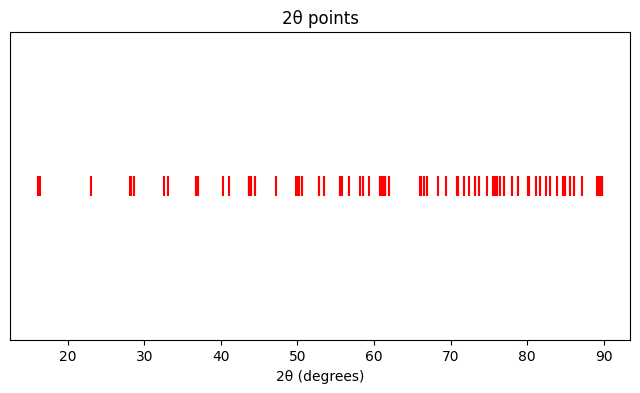

In [321]:
import matplotlib.pyplot as pl

plt.figure(figsize=(8,4))
plt.scatter(reflections, [1]*len(reflections), color='red', marker='|', s=200)  # vertical markers
plt.xlabel("2θ (degrees)")
plt.yticks([])  # no need for y-axis
plt.title("2θ points")
plt.show()

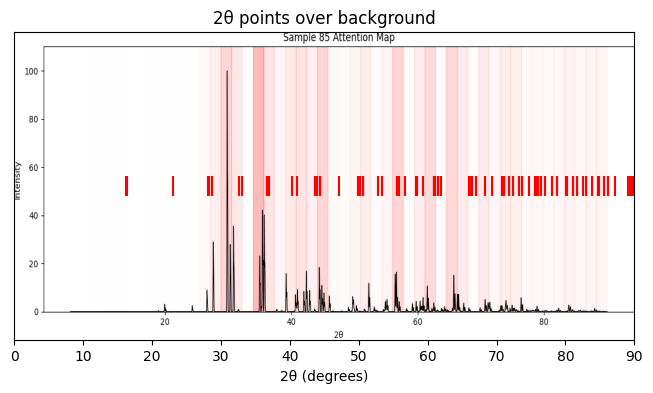

In [322]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load your background image
img = mpimg.imread("media_images_attention_overlay_sample_85_1_3b7612da85158a30ea8f.png")  # can be png, jpg, etc.

# Create figure and axis
fig, ax = plt.subplots(figsize=(8,4))

# Display the image as the background
ax.imshow(img, extent=[0, 90, 0, 1], aspect='auto')  

# Overlay 2theta points
ax.scatter(reflections, [0.5]*len(reflections), color='red', marker='|', s=200)  

ax.set_xlabel("2θ (degrees)")
ax.set_yticks([])
ax.set_title("2θ points over background")
plt.show()


## Generate allowed reflections (using Bravais lattice only)

In [323]:
from cctbx import uctbx
from math import ceil

def lattice_letter_from_sgnum(spacegroup_number: int) -> str:
    """
    Infer Bravais centering letter from an ITA space group number using spglib.
    Returns one of: P, A, B, C, I, F, R
    """
    t = spglib.get_spacegroup_type(spacegroup_number)
    # international_short like "P2_1/c", "Fm-3m", "R-3c", etc.
    return t["international_short"][0].upper()

def bravais_allows(h: int, k: int, l: int, lattice: str, r_setting: str = "hex") -> bool:
    """
    Centering-only reflection conditions.
    For R: assumes hex setting (most common in diffraction).
    """
    lattice = lattice.upper()
    if lattice == "P":
        return True
    if lattice == "I":
        return (h + k + l) % 2 == 0
    if lattice == "F":
        return (h % 2 == k % 2 == l % 2)  # all even or all odd
    if lattice == "A":
        return (k + l) % 2 == 0
    if lattice == "B":
        return (h + l) % 2 == 0
    if lattice == "C":
        return (h + k) % 2 == 0
    if lattice == "R":
        if r_setting != "hex":
            raise ValueError("R lattice here assumes hex axes (r_setting='hex').")
        return (-h + k + l) % 3 == 0

    raise ValueError(f"Unknown lattice type: {lattice}")

def get_reflections_bravais_only(
    spacegroup_number: int,
    unit_cell: tuple,
    twotheta_min: float = 5.0,
    twotheta_max: float = 90.0,
    wavelength: float = 1.541838,
    r_setting: str = "hex",
    dedupe_tol_deg: float = 1e-4,
):
    """
    Compute peak positions (2θ) using unit-cell metric, but keep/deny reflections
    using ONLY Bravais centering (no screw/glide absences).

    Inputs/outputs intentionally similar to your previous get_reflections().
    Returns: np.ndarray of sorted 2θ values (optionally de-duplicated by tolerance).
    """
    # Unit cell for d-spacing
    uc = uctbx.unit_cell(unit_cell)

    # Convert 2θ limits → d-spacing limits
    d_max = twotheta_to_d(twotheta_min, wavelength)  # largest d at lowest angle
    d_min = twotheta_to_d(twotheta_max, wavelength)  # smallest d at highest angle

    # Bravais lattice type from space group number
    lattice = lattice_letter_from_sgnum(spacegroup_number)

    # Reciprocal parameters for bounding h,k,l
    a_star, b_star, c_star, _, _, _ = uc.reciprocal_parameters()
    hmax = int(ceil(1.0 / (d_min * a_star)))
    kmax = int(ceil(1.0 / (d_min * b_star)))
    lmax = int(ceil(1.0 / (d_min * c_star)))

    twotheta = []

    for h in range(-hmax, hmax + 1):
        for k in range(-kmax, kmax + 1):
            for l in range(-lmax, lmax + 1):
                if (h, k, l) == (0, 0, 0):
                    continue

                # Bravais-lattice centering filter ONLY
                if not bravais_allows(h, k, l, lattice, r_setting=r_setting):
                    continue

                # d-spacing from metric
                d = uc.d((h, k, l))
                if d < d_min or d > d_max:
                    continue

                tt = d_to_twotheta(d, wavelength)
                if twotheta_min <= tt <= twotheta_max:
                    twotheta.append(tt)

    if not twotheta:
        return np.array([])

    twotheta = np.array(sorted(twotheta))

    # Optional: de-duplicate nearly identical peaks (metric degeneracies)
    if dedupe_tol_deg is not None and dedupe_tol_deg > 0:
        keep = [twotheta[0]]
        for x in twotheta[1:]:
            if abs(x - keep[-1]) > dedupe_tol_deg:
                keep.append(x)
        twotheta = np.array(keep)

    return twotheta

In [324]:
bravais_reflections = get_reflections_bravais_only(spacegroup_number, unit_cell)
print(bravais_reflections)

[ 9.30284504 13.43014044 16.14870504 16.36189752 18.6677192  21.06123214
 23.06739765 24.77863362 27.04932884 28.16047636 28.28666516 28.66217271
 31.31938086 31.66211195 32.62977617 33.06983691 34.00180263 35.42982725
 36.70976183 37.00821966 37.85530334 39.44412273 40.33997484 41.07200546
 41.40042857 42.20617614 42.87939811 43.63076176 43.71717986 43.97562088
 44.40369427 45.47059223 45.85669749 47.14241602 47.84084863 48.56130326
 49.84274773 49.92078497 50.15436246 50.5419042  50.82173092 51.86317816
 52.0904413  52.81510005 53.41199558 53.68114157 54.34491184 55.60241366
 55.77381393 55.81910243 56.68037872 57.08136201 57.62197135 58.22958592
 58.46600303 58.50993772 59.11179788 59.34602229 59.73562984 60.05485107
 60.85247776 60.92078401 61.12543196 61.46562034 61.9400499  62.63136089
 63.63483364 64.24965381 64.84447777 65.34633707 65.97692465 66.13183066
 66.17278267 66.49855842 66.95329826 67.31777435 67.81024249 68.36520335
 69.17365013 69.38881508 69.74720001 70.04128285 70

/tmp/ipykernel_4033192/3252324226.py:11: DeprecationWarning: dict interface is deprecated. Use attribute interface instead
  return t["international_short"][0].upper()


## Test both methods for first 10 structures

In [325]:
conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

for i in range(10):
    cursor.execute("""
        SELECT *
        FROM Structures
        WHERE structure_id = ?
    """, (hdf5_to_structure[i],))

    row = cursor.fetchone()

    #print(row)
    spacegroup_number = row[5]

    unit_cell = (
        row[7],   # a
        row[8],   # b
        row[9],   # c
        row[10],  # alpha
        row[11],  # beta
        row[12],  # gamma
    )
    bravais_reflections = get_reflections_bravais_only(spacegroup_number, unit_cell)
    reflections = get_reflections(spacegroup_number, unit_cell)

    print(bravais_reflections)
    print(reflections)
    #print(spacegroup_number, unit_cell)
conn.close()



/tmp/ipykernel_4033192/3252324226.py:11: DeprecationWarning: dict interface is deprecated. Use attribute interface instead
  return t["international_short"][0].upper()


[ 6.58845299 13.19881225 18.58785378 19.74051977 19.85364846 22.86548574
 26.5769182  27.3272263  32.48756722 32.62996077 33.18538848 33.39480962
 35.20529213 37.68870962 38.30336857 38.36514314 38.48844061 40.09944342
 40.33680212 42.45204222 42.95347916 44.75786466 46.711004   47.28081251
 47.4370725  50.59098875 51.0790228  51.22661332 51.37389908 52.52352223
 52.71639569 54.73645848 54.87128453 56.38588336 57.95913048 58.04948799
 58.32002978 58.40443624 58.67394885 59.72786359 61.89510581 61.98194551
 62.11207397 62.28533579 64.85828678 65.11197693 65.61256903 66.6026923
 68.03549883 68.36563168 68.44291903 68.56645817 69.65845009 70.14804794
 71.22406446 71.62324928 71.66361906 71.86532708 72.02652607 72.81537435
 72.97572909 73.29602826 74.43290625 74.78562692 75.14269206 77.51390831
 77.7492643  77.94035728 78.05787233 78.41011399 79.44968422 80.48091722
 80.86437435 80.98077889 81.44602691 82.01234563 82.16708023 82.47637824
 83.80790284 83.91871548 84.2653974  85.17453078 86.

[13.00680803 13.69729339 18.93211762 23.83954585 26.18507925 27.24911053
 27.59534364 29.66504507 30.61771966 35.70287592 36.78174849 38.40727867
 39.17089213 39.72776195 41.92305475 42.21316236 44.0786066  45.70959175
 46.86097977 48.79739387 49.05523303 50.10250597 50.72323464 50.92892206
 52.7979712  53.87894349 55.24893002 55.87130985 56.21369344 56.97773417
 58.15269541 58.71413897 59.1272751  59.72345213 61.59281688 62.63574394
 63.74683542 64.27900996 64.67111186 66.24876331 66.46095321 67.0196503
 67.84523004 68.98678806 69.08275593 70.5164613  70.72251302 71.69623346
 72.53400234 73.20144376 74.14140527 74.7310079  75.62797497 75.82854085
 76.5775946  76.77734616 77.30404992 78.08434035 78.2472586  79.25834231
 79.74485415 80.10422813 80.821813   82.27271036 82.55920722 83.20198797
 84.10959382 84.19967679 84.68030562 85.62064102 86.66937545 87.18340322
 87.25332644 89.00833819 89.09796501 89.93019965]
[13.69729339 23.83954585 26.18507925 27.24911053 27.59534364 29.66504507
 2

In [326]:
# individual test with index

conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

for i in range(1):
    cursor.execute("""
        SELECT *
        FROM Structures
        WHERE structure_id = ?
    """, (hdf5_to_structure[sample_index],))

    row = cursor.fetchone()

    #print(row)
    spacegroup_number = row[5]

    unit_cell = (
        row[7],   # a
        row[8],   # b
        row[9],   # c
        row[10],  # alpha
        row[11],  # beta
        row[12],  # gamma
    )
    bravais_reflections = get_reflections_bravais_only(spacegroup_number, unit_cell)
    reflections = get_reflections(spacegroup_number, unit_cell)

    print(bravais_reflections)
    print(reflections)
    #print(spacegroup_number, unit_cell)
conn.close()

[ 9.30284504 13.43014044 16.14870504 16.36189752 18.6677192  21.06123214
 23.06739765 24.77863362 27.04932884 28.16047636 28.28666516 28.66217271
 31.31938086 31.66211195 32.62977617 33.06983691 34.00180263 35.42982725
 36.70976183 37.00821966 37.85530334 39.44412273 40.33997484 41.07200546
 41.40042857 42.20617614 42.87939811 43.63076176 43.71717986 43.97562088
 44.40369427 45.47059223 45.85669749 47.14241602 47.84084863 48.56130326
 49.84274773 49.92078497 50.15436246 50.5419042  50.82173092 51.86317816
 52.0904413  52.81510005 53.41199558 53.68114157 54.34491184 55.60241366
 55.77381393 55.81910243 56.68037872 57.08136201 57.62197135 58.22958592
 58.46600303 58.50993772 59.11179788 59.34602229 59.73562984 60.05485107
 60.85247776 60.92078401 61.12543196 61.46562034 61.9400499  62.63136089
 63.63483364 64.24965381 64.84447777 65.34633707 65.97692465 66.13183066
 66.17278267 66.49855842 66.95329826 67.31777435 67.81024249 68.36520335
 69.17365013 69.38881508 69.74720001 70.04128285 70

/tmp/ipykernel_4033192/3252324226.py:11: DeprecationWarning: dict interface is deprecated. Use attribute interface instead
  return t["international_short"][0].upper()


In [327]:
def get_reflections_with_hkl(
    spacegroup_number,
    unit_cell,
    twotheta_min=5.0,
    twotheta_max=90.0,
    wavelength=1.541838,
):
    symm = crystal.symmetry(unit_cell=unit_cell, space_group=spacegroup_number)
    d_max = twotheta_to_d(twotheta_min, wavelength)
    d_min = twotheta_to_d(twotheta_max, wavelength)
    miller_set = symm.build_miller_set(anomalous_flag=False, d_min=d_min, d_max=d_max)
    uc = symm.unit_cell()

    results = []
    for hkl in miller_set.indices():
        d_hkl = uc.d(hkl)
        tt = d_to_twotheta(d_hkl, wavelength)
        results.append((tt, hkl))

    # Sort by 2θ
    results.sort(key=lambda x: x[0])
    twotheta = np.array([r[0] for r in results])
    hkls = [r[1] for r in results]
    return twotheta, hkls

In [328]:
def plot_pattern_with_hkl(twotheta_pattern, intensity_pattern, twotheta_peaks, hkls, n_labels=10):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(twotheta_pattern, intensity_pattern, 'k-', linewidth=0.8)

    # Find intensity at each peak position by interpolation
    peak_intensities = np.interp(twotheta_peaks, twotheta_pattern, intensity_pattern)

    # Label only the top N peaks by intensity
    top_idx = np.argsort(peak_intensities)[-n_labels:]

    for i in top_idx:
        h, k, l = hkls[i]
        ax.annotate(
            f"({h}{k}{l})",
            xy=(twotheta_peaks[i], peak_intensities[i]),
            xytext=(0, 8),
            textcoords="offset points",
            ha='center',
            fontsize=7,
            rotation=90,
        )

    ax.set_xlabel("2θ (degrees)")
    ax.set_ylabel("Intensity")
    ax.set_title("XRD Pattern")
    plt.tight_layout()
    plt.show()

In [329]:
twotheta_peaks, hkls = get_reflections_with_hkl(spacegroup_number, unit_cell)

In [330]:
spacegroup_number = row[5]   # space_group
unit_cell = (
    row[7],                  # lattice_a
    row[8],                  # lattice_b
    row[9],                  # lattice_c
    row[10],                 # alpha
    row[11],                 # beta
    row[12],                 # gamma
)

twotheta_pattern, intensity_pattern = generate_diffraction_pattern_helper(
    spacegroup_number=spacegroup_number,
    unit_cell=unit_cell,
    wavelength=1.541838,
    twotheta_min=5.0,
    twotheta_max=90.0,
    twothstep=0.01,
    u=0.01,
    v=-0.01,
    w=0.02,
    peak_scale=1000,
)

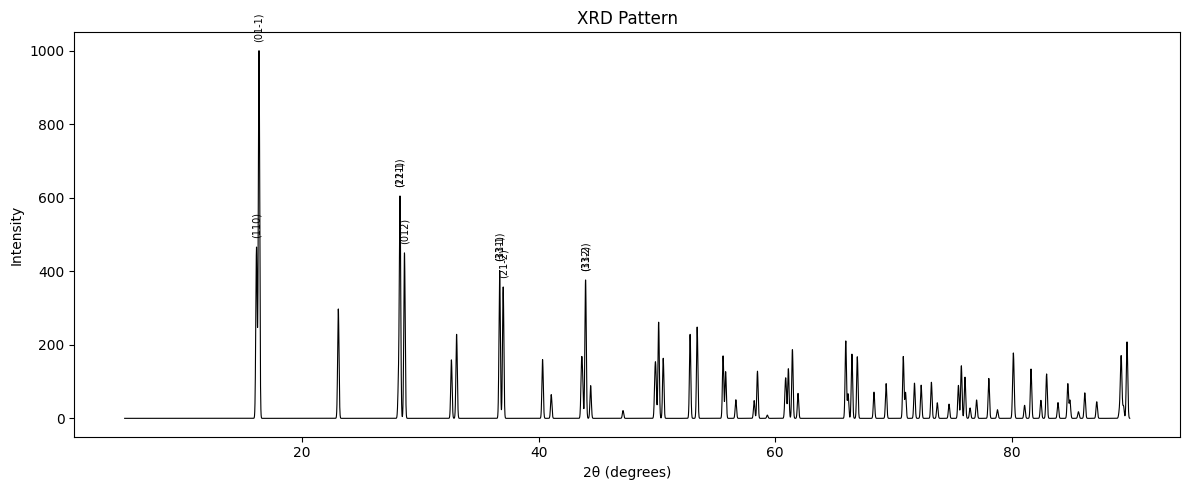

In [331]:

#twotheta_pattern, intensity_pattern = generate_diffraction_pattern_helper(spacegroup_number, unit_cell)
plot_pattern_with_hkl(twotheta_pattern, intensity_pattern, twotheta_peaks, hkls, n_labels=10)

In [332]:
def plot_pattern_with_hkl_attn(
    twotheta_pattern,
    intensity_pattern,
    twotheta_peaks,
    hkls,
    attn_profile=None,
    n_labels=10,
    sample_index=0,
    pattern_id=None,
    crystal_system=None,
):
    peak_max = intensity_pattern.max()
    hkl_buffer = 0.20 * peak_max if n_labels > 0 else 0.10 * peak_max
    y_max = peak_max + hkl_buffer

    fig, ax = plt.subplots(figsize=(12, 5))

    # ── Attention overlay ──────────────────────────────────────────
    if attn_profile is not None:
        attn_norm = (attn_profile - attn_profile.min()) / (attn_profile.max() - attn_profile.min() + 1e-8)
        num_bins = 50
        bin_edges = np.linspace(twotheta_pattern[0], twotheta_pattern[-1], num_bins + 1)
        bin_indices = np.digitize(twotheta_pattern, bin_edges) - 1
        for i in range(num_bins):
            mask = bin_indices == i
            if np.any(mask):
                ax.fill_between(
                    twotheta_pattern[mask], 0, y_max,
                    color=(1.0, 0, 0, attn_norm[mask].mean()),
                    step='mid'
                )

    # ── XRD pattern ───────────────────────────────────────────────
    ax.plot(twotheta_pattern, intensity_pattern, 'k-', linewidth=0.8)

    # ── HKL labels ────────────────────────────────────────────────
    peak_intensities = np.interp(twotheta_peaks, twotheta_pattern, intensity_pattern)
    top_idx = np.argsort(peak_intensities)[-n_labels:]

    for i in top_idx:
        h, k, l = hkls[i]
        ax.annotate(
            f"({h}{k}{l})",
            xy=(twotheta_peaks[i], peak_intensities[i]),
            xytext=(0, 8),
            textcoords="offset points",
            ha='center',
            fontsize=7,
            rotation=45,
        )

    ax.set_ylim(0, y_max)
    ax.set_xlabel("2θ (degrees)")
    ax.set_ylabel("Intensity")
    ax.set_title(f"XRD Pattern {pattern_id} - Index {sample_index} - {crystal_system}")
    plt.tight_layout()
    plt.show()

In [333]:
def plot_pattern_with_hkl_attn_offset(
    twotheta_pattern,
    intensity_pattern,
    twotheta_peaks,
    hkls,
    attn_profile=None,
    n_labels=10,
    sample_index=0,
    pattern_id=None,
    crystal_system=None,
    min_x_sep=0.8,   # minimum 2θ separation before staggering
    y_step=0.06,     # stagger step as fraction of peak_max
):
    peak_max = intensity_pattern.max()
    hkl_buffer = 0.20 * peak_max if n_labels > 0 else 0.10 * peak_max
    y_max = peak_max + hkl_buffer

    fig, ax = plt.subplots(figsize=(12, 5))

    # ── Attention overlay ──────────────────────────────────────────
    if attn_profile is not None:
        attn_norm = (attn_profile - attn_profile.min()) / (attn_profile.max() - attn_profile.min() + 1e-8)
        num_bins = 50
        bin_edges = np.linspace(twotheta_pattern[0], twotheta_pattern[-1], num_bins + 1)
        bin_indices = np.digitize(twotheta_pattern, bin_edges) - 1
        for i in range(num_bins):
            mask = bin_indices == i
            if np.any(mask):
                ax.fill_between(
                    twotheta_pattern[mask], 0, y_max,
                    color=(1.0, 0, 0, attn_norm[mask].mean()),
                    step='mid'
                )

    # ── XRD pattern ───────────────────────────────────────────────
    ax.plot(twotheta_pattern, intensity_pattern, 'k-', linewidth=0.8)

    # ── HKL labels with stagger ───────────────────────────────────
    peak_intensities = np.interp(twotheta_peaks, twotheta_pattern, intensity_pattern)
    top_idx = np.argsort(peak_intensities)[-n_labels:]

    # Track placed labels as (x, y) to detect collisions
    placed = []

    for i in top_idx:
        h, k, l = hkls[i]
        x = twotheta_peaks[i]
        base_y = peak_intensities[i] + 0.02 * peak_max

        # Find y offset — bump up if too close in x to an existing label
        y = base_y
        for px, py in placed:
            if abs(x - px) < min_x_sep:
                y = max(y, py + y_step * peak_max)

        placed.append((x, y))

        ax.annotate(
            f"({h}{k}{l})",
            xy=(x, peak_intensities[i]),
            xytext=(x, y),
            xycoords='data',
            textcoords='data',
            ha='center',
            va='bottom',
            fontsize=7,
            rotation=45,
            arrowprops=dict(arrowstyle="-", color='gray', lw=0.5),
        )

    ax.set_ylim(0, y_max)
    ax.set_xlabel("2θ (degrees)")
    ax.set_ylabel("Intensity")
    ax.set_title(f"XRD Pattern {pattern_id} - Index {sample_index} - {crystal_system}")
    plt.tight_layout()
    plt.show()

In [334]:
def plot_pattern_with_hkl_attn_offset_no_limit(
    twotheta_pattern,
    intensity_pattern,
    twotheta_peaks,
    hkls,
    attn_profile=None,
    n_labels=10,
    sample_index=0,
    pattern_id=None,
    crystal_system=None,
    min_x_sep=1.0,
    y_step=0.06,
):
    """
    XRD pattern with attention overlay and staggered HKL annotations.
    Pass n_labels=0 to label all HKLs.
    """
    peak_max = intensity_pattern.max()
    hkl_buffer = 0.20 * peak_max if n_labels == 0 else (0.20 * peak_max if n_labels > 0 else 0.10 * peak_max)
    y_max = peak_max + hkl_buffer

    fig, ax = plt.subplots(figsize=(20, 8))

    if attn_profile is not None:
        attn_norm = (attn_profile - attn_profile.min()) / (attn_profile.max() - attn_profile.min() + 1e-8)
        num_bins = 50
        bin_edges = np.linspace(twotheta_pattern[0], twotheta_pattern[-1], num_bins + 1)
        bin_indices = np.digitize(twotheta_pattern, bin_edges) - 1
        for i in range(num_bins):
            mask = bin_indices == i
            if np.any(mask):
                ax.fill_between(
                    twotheta_pattern[mask], 0, y_max,
                    color=(1.0, 0, 0, attn_norm[mask].mean()),
                    step='mid'
                )

    ax.plot(twotheta_pattern, intensity_pattern, 'k-', linewidth=0.8)

    peak_intensities = np.interp(twotheta_peaks, twotheta_pattern, intensity_pattern)
    top_idx = np.arange(len(hkls)) if n_labels == 0 else np.argsort(peak_intensities)[-n_labels:]
    print(f"Total HKLs: {len(top_idx)}")

    placed = []
    for i in top_idx:
        h, k, l = hkls[i]
        x = twotheta_peaks[i]
        base_y = peak_intensities[i] + 0.02 * peak_max

        y = base_y
        for px, py in placed:
            if abs(x - px) < min_x_sep:
                y = max(y, py + y_step * peak_max)
        placed.append((x, y))

        ax.annotate(
            f"({h}{k}{l})",
            xy=(x, peak_intensities[i]),
            xytext=(x, y),
            xycoords='data',
            textcoords='data',
            ha='center',
            va='bottom',
            fontsize=6,
            rotation=45,
            arrowprops=dict(arrowstyle="-", color='gray', lw=0.5),
        )

    ax.set_ylim(0, y_max)
    ax.set_xlabel("2θ (degrees)")
    ax.set_ylabel("Intensity")
    ax.set_title(f"XRD Pattern {pattern_id} - Index {sample_index} - {crystal_system}")
    plt.tight_layout()
    plt.show()


In [ ]:
# Load
#attn_profile = np.load("attn_profile_25.npy")

# Reconstruct two_theta to match profile length
#two_theta_min, two_theta_max = 10.0, 90.0
#two_theta = np.linspace(two_theta_min, two_theta_max, len(attn_profile))

# Call
#plot_pattern_with_hkl_attn(
#    twotheta_pattern=two_theta,
#    intensity_pattern=intensity_pattern,
#    twotheta_peaks=twotheta_peaks,
#    hkls=hkls,
#    attn_profile=attn_profile,
#    n_labels=10,
#)

In [336]:
len(intensity_pattern) # shouldn't this be 8501

8500

In [337]:
#attn_profile = np.load("attn_profile_25.npy")

## Reconstruct two_theta from intensity_pattern length (source of truth)
#two_theta_min, two_theta_max = 5.0, 90.0
#two_theta = np.linspace(two_theta_min, two_theta_max, len(intensity_pattern))

## Align attn_profile to match
#attn_profile = np.interp(
#    np.linspace(0, 1, len(intensity_pattern)),
#    np.linspace(0, 1, len(attn_profile)),
#    attn_profile
#)

#plot_pattern_with_hkl_attn(
#    twotheta_pattern=two_theta,
#    intensity_pattern=intensity_pattern,
#    twotheta_peaks=twotheta_peaks,
#    hkls=hkls,
#    attn_profile=attn_profile,
#    n_labels=10,
#)

In [338]:
# Adapted from source: https://github.com/linresearchgroup/ViT_Materials_Spectra

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchtune.modules import RotaryPositionalEmbeddings
from functools import partial

class EncoderBlock(nn.Module):
    def __init__(self,
                 dim,
                 num_heads,
                 mlp_ratio=4.,
                 qkv_bias=False,
                 qk_scale=None,
                 drop_ratio=0.,
                 attn_drop_ratio=0.,
                 drop_path_ratio=0.,
                 act_layer=nn.GELU,
                 norm_layer=nn.LayerNorm,
                 use_rope=False):
        super(EncoderBlock, self).__init__()
        self.norm1 = norm_layer(dim)
        self.use_rope = use_rope
        self.attn = Attention(dim, num_heads=num_heads, qkv_bias=qkv_bias, qk_scale=qk_scale,
                              attn_drop_ratio=attn_drop_ratio, proj_drop_ratio=drop_ratio, use_rope=use_rope)
        self.drop_path = DropPath(
            drop_path_ratio) if drop_path_ratio > 0. else nn.Identity()
        self.norm2 = norm_layer(dim)
        mlp_hidden_dim = int(dim * mlp_ratio)
        self.mlp = Mlp(in_features=dim, hidden_features=mlp_hidden_dim,
                       act_layer=act_layer, drop=drop_ratio)

    # def forward(self, x):
    #     x = x + self.drop_path(self.attn(self.norm1(x)))
    #     x = x + self.drop_path(self.mlp(self.norm2(x)))
    #     return x
    
    def forward(self, x, return_attn=False):
        # compute attention output
        # attn_out = self.attn(self.norm1(x))

        if return_attn:
            attn_out, attn_map = self.attn(self.norm1(x), return_attn=True)
        else:
            attn_out = self.attn(self.norm1(x))
            attn_map = None

        x = x + self.drop_path(attn_out)
        x = x + self.drop_path(self.mlp(self.norm2(x)))

        if return_attn:
            return x, attn_map  # return the attention map, not projected output
        else:
            return x

class Attention(nn.Module):
    def __init__(self,
                 dim,
                 num_heads=2,
                 qkv_bias=False,
                 qk_scale=None,
                 attn_drop_ratio=0.,
                 proj_drop_ratio=0.,
                 use_rope=False):
        super(Attention, self).__init__()
        self.use_rope = use_rope

        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = qk_scale or self.head_dim ** -0.5
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop_ratio)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop_ratio)

        if self.use_rope:
#            print("Using RoPE")
            self.rope = RotaryPositionalEmbeddings(self.head_dim)

    def forward(self, x, return_attn=False):
        # [batch_size, num_patches + 1, total_embed_dim]
        B, N, C = x.shape
        # qkv(): -> [batch_size, num_patches + 1, 3 * total_embed_dim]
        # reshape: -> [batch_size, num_patches + 1, 3, num_heads, embed_dim_per_head]
        # permute: -> [3, batch_size, num_heads, num_patches + 1, embed_dim_per_head]
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        # [batch_size, num_heads, num_patches + 1, embed_dim_per_head]
        # make torchscript happy (cannot use tensor as tuple)
        q, k, v = qkv[0], qkv[1], qkv[2]
        # transpose: -> [batch_size, num_heads, embed_dim_per_head, num_patches + 1]
        # @: multiply -> [batch_size, num_heads, num_patches + 1, num_patches + 1]

        if self.use_rope:
#            print(f"[RoPE] Rotary embedding applied")
            q, k = self.rope(q), self.rope(k)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)
        # @: multiply -> [batch_size, num_heads, num_patches + 1, embed_dim_per_head]
        # transpose: -> [batch_size, num_patches + 1, num_heads, embed_dim_per_head]
        # reshape: -> [batch_size, num_patches + 1, total_embed_dim]
        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj(x)
        x = self.proj_drop(x)

        # for inference
        if return_attn:
            # Return both the projected output and the raw attention weights
            return x, attn
        
        return x

class Mlp(nn.Module):

    def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = act_layer()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x

class PatchEmbed1D(nn.Module):
    def __init__(self, spec_length, patch_size, embed_dim):
        super().__init__()
        self.proj = nn.Conv1d(1, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        self.num_patches = spec_length // patch_size

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)  # (B, 1, L)

        # Pad to multiple of patch size
        pad_len = (self.patch_size - x.shape[-1] % self.patch_size) % self.patch_size
        if pad_len > 0:
            x = F.pad(x, (0, pad_len), value=0)

        x = self.proj(x)  # (B, embed_dim, num_patches)
        return x.transpose(1, 2)  # (B, num_patches, embed_dim)


'''
def Spectra_Embedding(x, spec_length, embed_dim):
    batch_size = x.shape[0]
    new_spec_length = (spec_length // embed_dim) * embed_dim
    x = x[:, :new_spec_length]
    x = torch.reshape(x, (batch_size, spec_length // embed_dim, embed_dim))
    return x

def Spectra_Embedding_old(x, spec_length, embed_dim):

    batch_size = x.shape[0]
    x = torch.reshape(x, (batch_size, spec_length // embed_dim, embed_dim))
    return x

def Spectra_Embedding_enlong(x, spec_length, embed_dim):
    batch_size = x.shape[0]
    remainder = spec_length % embed_dim
    if remainder != 0:
        pad = embed_dim - remainder
        x = F.pad(x, (0, pad))
    x = torch.reshape(x, (batch_size, -1, embed_dim))
    return x
'''
class MLPHead(nn.Module):
    """Optional non-linear head for ViT fine-tuning."""
    def __init__(self, embed_dim, num_classes, hidden_dim=None, drop=0.):
        super().__init__()
        hidden_dim = hidden_dim or embed_dim
        self.fc1 = nn.Linear(embed_dim, hidden_dim)
        self.act = nn.GELU()
        self.drop = nn.Dropout(drop)
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        return x
    
class VIT(nn.Module):
    def __init__(self, spec_length=2000, patch_size=10, num_output=1,
                 embed_dim=40, depth=12, num_heads=2, mlp_ratio=4.0, qkv_bias=True,
                 qk_scale=None, drop_ratio=0.,
                 attn_drop_ratio=0., drop_path_ratio=0., norm_layer=None,
                 act_layer=None, use_rope=False, use_mlp_head=False, mlp_head_hidden_dim=None):

        # MSTransformer
        super(VIT, self).__init__()
        self.num_classes = num_output
        self.spec_length = spec_length
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        norm_layer = norm_layer or partial(nn.LayerNorm, eps=1e-6)
        act_layer = act_layer or nn.GELU
        self.use_mlp_head = use_mlp_head
        self.mlp_head_hidden_dim = mlp_head_hidden_dim
        
        self.patch_embed = PatchEmbed1D(spec_length, patch_size, embed_dim)
        #self.num_patches = spec_length // patch_size
        # Calculate padded spec length
        padded_spec_length = (spec_length + patch_size - 1) // patch_size * patch_size
        self.num_patches = padded_spec_length // patch_size

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))  # +1 for cls
        self.pos_drop = nn.Dropout(p=drop_ratio)
        dpr = [x.item() for x in torch.linspace(0, drop_path_ratio, depth)]
        self.use_rope = use_rope

        self.blocks = nn.Sequential(*[
            EncoderBlock(dim=embed_dim, num_heads=num_heads, mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, qk_scale=qk_scale,
                        drop_ratio=drop_ratio, attn_drop_ratio=attn_drop_ratio, drop_path_ratio=dpr[i],
                        norm_layer=norm_layer, act_layer=act_layer, use_rope=use_rope)
            for i in range(depth)
        ])
        self.norm = norm_layer(embed_dim)



        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(_init_vit_weights)

        if self.use_mlp_head:
            self.head = MLPHead(embed_dim, num_output, hidden_dim=mlp_head_hidden_dim, drop=drop_ratio)
        else:
            self.head = nn.Linear(embed_dim, num_output)


    def forward(self, x, return_cls_embedding=False):
        x = self.patch_embed(x)  # (B, num_patches, embed_dim)
        B, N, _ = x.shape

        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)  # (B, N+1, embed_dim)

        if x.size(1) != self.pos_embed.size(1):
            # Resize positional embedding to match
            pos_embed = F.interpolate(
                self.pos_embed.transpose(1, 2),
                size=x.size(1),
                mode='linear',
                align_corners=False
            ).transpose(1, 2)
        else:
            pos_embed = self.pos_embed

        x = x + pos_embed

        x = self.pos_drop(x)

        for blk in self.blocks:
            x = blk(x)

        x = self.norm(x)
        cls_out = x[:, 0]

        return cls_out if return_cls_embedding else self.head(cls_out)

    def forward_with_attn(self, x, return_cls_embedding=False):
        """
        Forward pass that returns attention weights for CAM-style visualization.
        """
        x = self.patch_embed(x)  # (B, num_patches, embed_dim)
        B, N, _ = x.shape

        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)  # (B, N+1, embed_dim)

        if x.size(1) != self.pos_embed.size(1):
            pos_embed = F.interpolate(
                self.pos_embed.transpose(1, 2),
                size=x.size(1),
                mode='linear',
                align_corners=False
            ).transpose(1, 2)
        else:
            pos_embed = self.pos_embed

        x = x + pos_embed
        x = self.pos_drop(x)

        attn_weights_list = []
        for blk in self.blocks:
            if hasattr(blk, "attn"):
                x, attn = blk(x, return_attn=True)  # block must support return_attn
                attn_weights_list.append(attn)
            else:
                x = blk(x)

        x = self.norm(x)
        cls_out = x[:, 0]

        return (cls_out if return_cls_embedding else self.head(cls_out), attn_weights_list)


def _init_vit_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.trunc_normal_(m.weight, std=.01)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.LayerNorm):
        nn.init.zeros_(m.bias)
        nn.init.ones_(m.weight)

def VIT_model(spec_length=2251,num_output: int = 1, patch_size=10, embed_dim=40, depth=12, num_heads=2, mlp_ratio=4.0, drop_ratio = 0., local_rank=0, use_rope=False, use_mlp_head=False, mlp_head_hidden_dim=None):
    model = VIT(spec_length=spec_length,
                              patch_size=patch_size,
                              embed_dim=embed_dim,
                              depth=depth,
                              num_heads=num_heads,
                              num_output=num_output,
                              mlp_ratio=mlp_ratio,
                              drop_ratio=drop_ratio,
                              use_rope=use_rope,
                              use_mlp_head=use_mlp_head,
                              mlp_head_hidden_dim=mlp_head_hidden_dim)

    return model

In [339]:
spec_length=8501
num_classes=99
patch_size=25
embed_dim=256
depth=12
num_heads=8
mlp_ratio=4.0
drop_ratio=0.0
use_rope=False
use_mlp=False
mlp_hidden_dim=512
checkpoint='/scratch/10486/UserB/Models/xrd_model_pi7r8pah.pth'

In [340]:
    # Select device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

Using device: cuda


In [341]:
# --- Load model ---
model = VIT_model(
    spec_length=spec_length,
    num_output=num_classes,
    patch_size=patch_size,
    embed_dim=embed_dim,
    depth=depth,
    num_heads=num_heads,
    mlp_ratio=mlp_ratio,
    drop_ratio=drop_ratio,
    use_rope=use_rope,
    use_mlp_head=use_mlp,
    mlp_head_hidden_dim=mlp_hidden_dim
)
# --- Load checkpoint ---
checkpoint = torch.load(checkpoint, map_location=device)

state_dict = checkpoint.get("model", checkpoint)  # handle case where it's nested

# Remove "module." prefix if present
from collections import OrderedDict
new_state_dict = OrderedDict()
for k, v in state_dict.items():
    name = k.replace("module.", "")  # remove "module." if it exists
    new_state_dict[name] = v

# Load into model
model.load_state_dict(new_state_dict, strict=False)

# Move to device
model = model.to(device)

model.eval()

VIT(
  (patch_embed): PatchEmbed1D(
    (proj): Conv1d(1, 256, kernel_size=(25,), stride=(25,))
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (blocks): Sequential(
    (0): EncoderBlock(
      (norm1): LayerNorm((256,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=256, out_features=768, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=256, out_features=256, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((256,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=256, out_features=1024, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1024, out_features=256, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
    (1): EncoderBlock(
      (norm1): LayerNorm((256,), eps=1e-06, elementwise_affine=True)
      (attn): Attenti

In [342]:
def project_attention_to_2theta(attn_map, spec_length, two_theta_range):
    """
    Project attention weights back to 2θ domain.
    Ensures output length exactly matches spectrum length.
    Args:
        attn_map: torch.Tensor (num_heads, num_tokens, num_tokens)
        spec_length: int, length of spectrum (e.g. 3041)
        two_theta_range: tuple (min_2θ, max_2θ)
    Returns:
        two_theta: np.array of shape (spec_length,)
        attn_profile: np.array of shape (spec_length,)
    """
    # average attention across heads and CLS → patch tokens
    attn_cls = attn_map.mean(0)[0, 1:]  # (num_patches,)
    attn_cls = attn_cls / attn_cls.sum()

    # interpolate attention to exactly match spectrum length
    attn_profile = np.interp(
        np.arange(spec_length),
        np.linspace(0, spec_length - 1, len(attn_cls)),
        attn_cls.cpu().numpy()
    )

    # create two_theta to exactly match spec_length
    two_theta = np.linspace(two_theta_range[0], two_theta_range[1], spec_length)

    return two_theta, attn_profile

In [343]:
len(intensity_pattern)

8500

In [344]:
intensity_pattern_padded = np.append(intensity_pattern, 0.0)


In [345]:
len(intensity_pattern_padded)

8501

In [346]:
spectrum = torch.tensor(intensity_pattern_padded, dtype=torch.float32).unsqueeze(0).to(device)

In [347]:

# 2️⃣ Run model to get attention
with torch.no_grad():
    logits, attn_maps = model.forward_with_attn(spectrum)

last_attn = attn_maps[-1]
if isinstance(last_attn, (list, tuple)):
    last_attn = last_attn[0]
if last_attn.ndim == 4:  # B, heads, N, N
    last_attn = last_attn[0]

# 3️⃣ Project attention to spectrum length
two_theta, attn_profile = project_attention_to_2theta(
    last_attn,
    spec_length=spectrum.shape[1],
    two_theta_range=(two_theta_min, two_theta_max)
)


In [348]:
row[0]

'2a91c741-6c57-4b06-a775-8ccedcdbf0e3'

In [349]:
row[4]

'Trigonal'

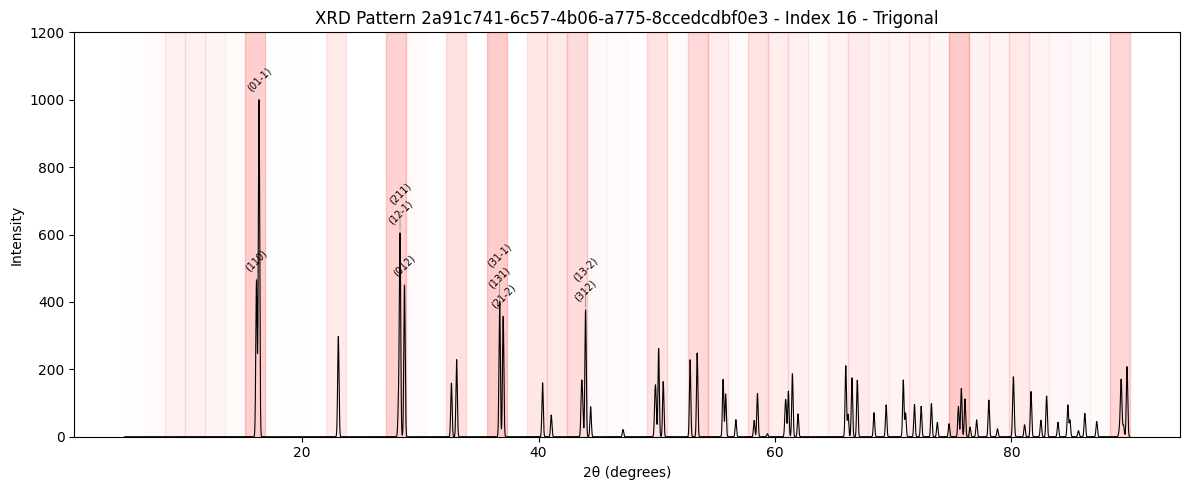

In [350]:
#attn_profile = np.load("attn_profile_25.npy")

# Reconstruct two_theta from intensity_pattern length (source of truth)
two_theta_min, two_theta_max = 5.0, 90.0
two_theta = np.linspace(two_theta_min, two_theta_max, len(intensity_pattern))

# Align attn_profile to match
attn_profile = np.interp(
    np.linspace(0, 1, len(intensity_pattern)),
    np.linspace(0, 1, len(attn_profile)),
    attn_profile
)

plot_pattern_with_hkl_attn_offset(
    twotheta_pattern=two_theta,
    intensity_pattern=intensity_pattern,
    twotheta_peaks=twotheta_peaks,
    hkls=hkls,
    attn_profile=attn_profile,
    n_labels=10,
    sample_index=sample_index,
    pattern_id=row[0],
    crystal_system=row[4]
)

Total HKLs: 124


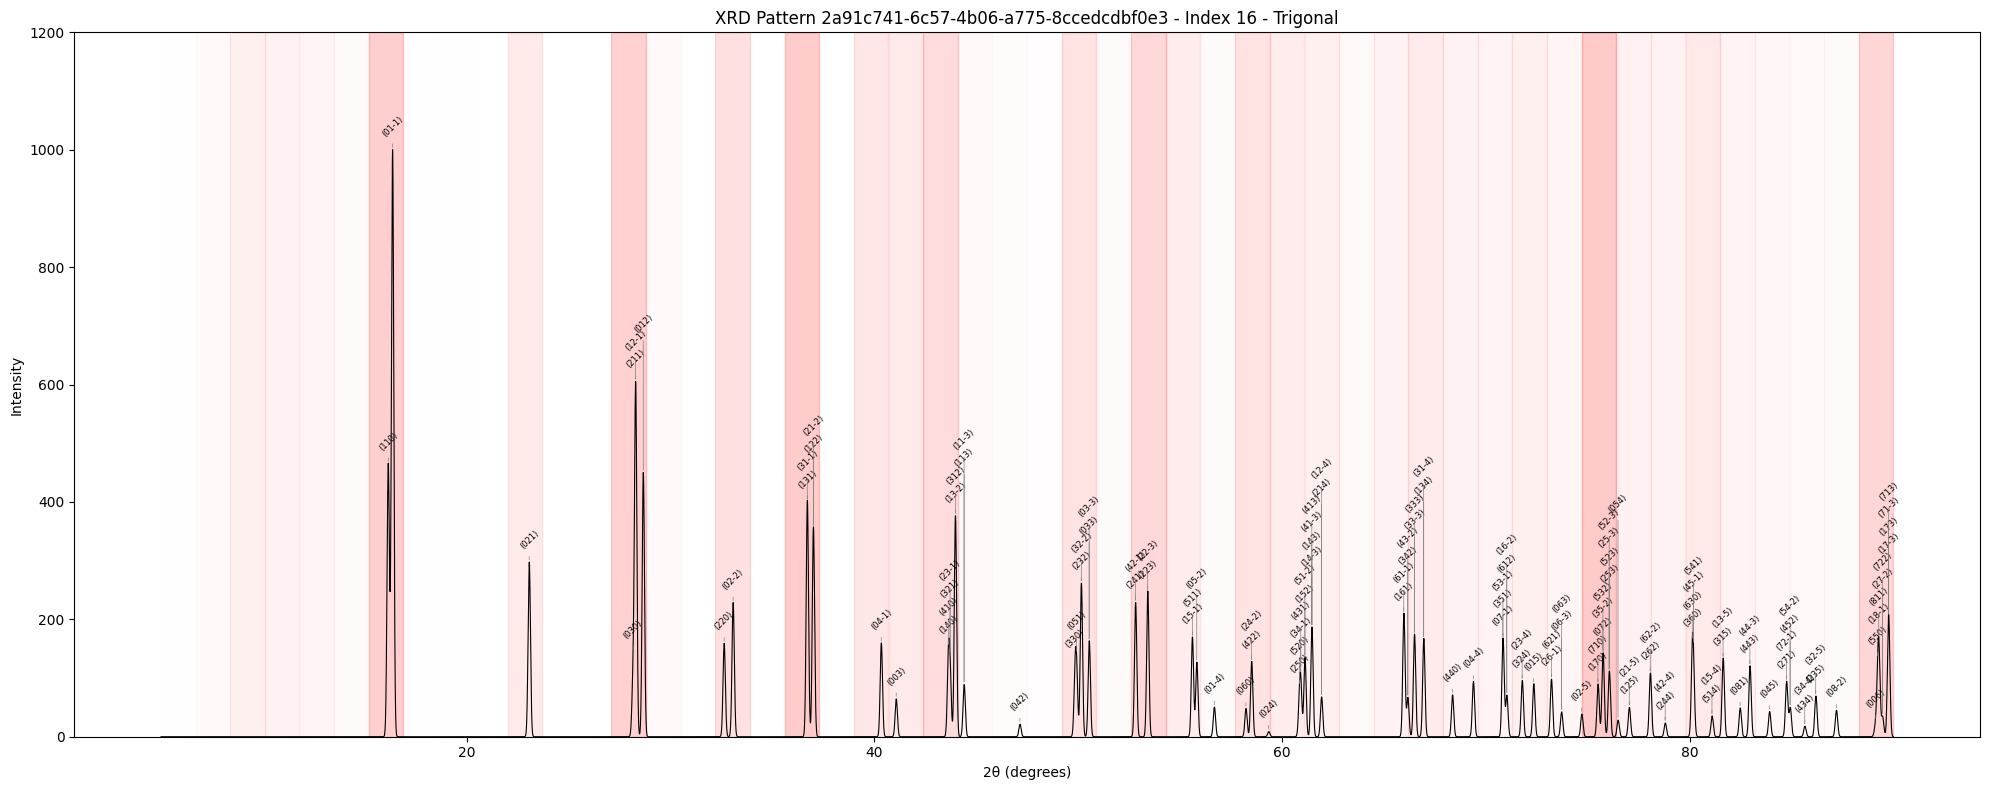

In [351]:

plot_pattern_with_hkl_attn_offset_no_limit(
    twotheta_pattern=two_theta,
    intensity_pattern=intensity_pattern,
    twotheta_peaks=twotheta_peaks,
    hkls=hkls,
    attn_profile=attn_profile,
    min_x_sep=0.5,
    y_step=0.03,
    n_labels=0,
    sample_index=sample_index,
    pattern_id=row[0],
    crystal_system=row[4]
)

In [352]:
def plot_predicted_vs_actual_single(
    model,
    spectrum,
    actual_label,
    device,
    sample_index=None,
    class_names=None,
    save_dir="./pred_plots",
):
    """
    Plot predicted vs actual extinction group for a single sample.

    Parameters
    ----------
    model : VIT model (eval mode)
    spectrum : np.ndarray  raw intensity array
    actual_label : int  actual extinction group (1-indexed)
    device : torch.device
    sample_index : int  optional, just for plot title/filename
    class_names : list of str  maps 0-indexed class to label name
    save_dir : str
    """
    import os, torch
    os.makedirs(save_dir, exist_ok=True)

    model.eval()

    spectrum_tensor = torch.tensor(spectrum, dtype=torch.float32).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(spectrum_tensor)
        probs = torch.softmax(logits, dim=-1).squeeze()
        top5_probs, top5_preds = torch.topk(probs, 5)

    pred = top5_preds[0].item()
    # actual_label is 1-indexed, model is 0-indexed
    actual_idx = actual_label - 1
    correct = pred == actual_idx

    pred_name = class_names[pred] if class_names else str(pred + 1)
    actual_name = class_names[actual_idx] if class_names else str(actual_label)

    # ── Bar chart ─────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(8, 4))

    colors = ["green" if top5_preds[i].item() == actual_idx else "steelblue" for i in range(5)]
    labels = [class_names[p.item()] if class_names else str(p.item() + 1) for p in top5_preds]

    bars = ax.barh(labels[::-1], top5_probs.cpu().numpy()[::-1], color=colors[::-1])
    ax.set_xlabel("Probability")
    ax.set_xlim(0, 1)
    ax.set_title(
        f"Sample {sample_index} — Actual: {actual_name} | Pred: {pred_name} "
        + ("✓" if correct else "✗"),
        color="green" if correct else "red"
    )

    for bar, prob in zip(bars, top5_probs.cpu().numpy()[::-1]):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
                f"{prob:.3f}", va='center', fontsize=9)

    plt.tight_layout()
    save_path = os.path.join(save_dir, f"pred_vs_actual_{sample_index}.png")
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()
    plt.close()

    print(f"Actual: {actual_name} | Predicted: {pred_name} | {'✓ Correct' if correct else '✗ Incorrect'}")

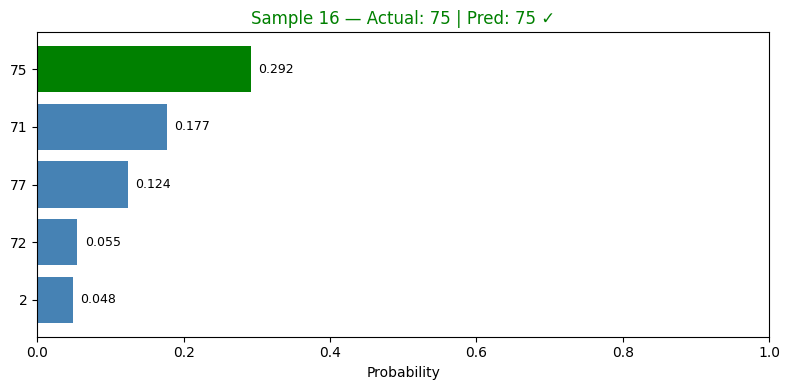

Actual: 75 | Predicted: 75 | ✓ Correct


In [353]:
actual_extinction_group = row[3]  # extinction_group column (1-indexed)

plot_predicted_vs_actual_single(
    model=model,
    spectrum=intensity_pattern_padded,
    actual_label=actual_extinction_group,
    device=device,
    sample_index=sample_index,
    class_names=[str(i) for i in range(1, 100)],
    save_dir="./pred_plots",
)